# 4. Storm Track Model (STM)

A storm track is a band of enhanced transient-eddy variance. A *storm track
model* asks: what variance does a **stochastic** transient forcing maintain
against dissipation, given the basic-state flow? For the linear system
$dx'/dt=\mathbf{A}x'+ \boldsymbol{\xi}(t)$ with white-in-time forcing of
covariance $\mathbf{Q}$, the **stationary response covariance**
$\mathbf{C}=\langle x'x'^{*}\rangle$ solves the **Lyapunov equation**

$$\mathbf{A}\mathbf{C} + \mathbf{C}\mathbf{A}^{*} = -\mathbf{Q},$$

whose variance map is the model's storm track (WK guide Ch. 4; Farrell & Ioannou;
Whitaker & Sardeshmukh 1998).

We build the STM on the **barotropic** operator (`lbmtools.Barotropic`). A single
non-divergent vorticity field has a clean energy norm and a well-behaved,
positive-definite covariance — whereas the full primitive-equation operator's
fast gravity waves make the Lyapunov covariance ill-posed. This is exactly the
barotropic storm-track model of Whitaker & Sardeshmukh.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")
root = os.path.abspath("")
while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "pylbm_isca")):
    root = os.path.dirname(root)
sys.path.insert(0, root)
sys.path.insert(0, os.path.join(root, "docs", "book"))
import numpy as np
import matplotlib.pyplot as plt
from pylbm_isca import Config, LBM, Spectral, VerticalGrid
from pylbm_isca.backend import asnumpy, gpu_available
import lbmtools as lt

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(nlon=64, nlat=32, nmax=21, device=DEVICE)   # T21 L20, runs offline
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = sp.lon_deg, sp.lat_deg, asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T21  64x32  L20  backend=gpu


## 4.1 A maintained storm track

A stable mid-latitude jet, stochastically forced white in vorticity. For each
zonal wavenumber we solve the Lyapunov equation for the covariance, draw samples
from it, and accumulate the **meridional-wind variance** $\overline{v'^2}$ — the
classic storm-track metric.

In [2]:
from scipy.linalg import solve_continuous_lyapunov
phi = np.deg2rad(lat)
u0, jetlat, jetw = 35.0, 45.0, 12.0
ujet = u0*np.exp(-((phi-np.deg2rad(jetlat))/np.deg2rad(jetw))**2)
bar = lt.Barotropic(sp, ujet[:, None]*np.ones((sp.nlat, sp.nlon)), drag_days=4.0)

rng = np.random.default_rng(0)
N = 150                                                  # samples per wavenumber
v2 = np.zeros(sp.nlat); unstable = 0
for m in range(1, 13):
    A, ns = bar.block(m)
    if np.linalg.eigvals(A).real.max() >= 0:            # Lyapunov needs stability
        unstable += 1; continue
    C = solve_continuous_lyapunov(A, -np.eye(len(ns)))  # Q = I (white vorticity)
    C = 0.5*(C + C.conj().T)
    ev, Umat = np.linalg.eigh(C); ev = np.clip(ev, 0, None)
    L = Umat @ np.diag(np.sqrt(ev))                     # C = L L*
    for _ in range(N):
        zc = (rng.standard_normal(len(ns)) + 1j*rng.standard_normal(len(ns)))
        coef = L @ (zc/np.sqrt(2))
        zs = np.zeros((sp.nmax+1, sp.nmax+1), complex); zs[m, ns] = coef
        _, vv = sp.vordiv_to_uv(sp.xp.asarray(zs), sp.xp.zeros_like(sp.xp.asarray(zs)))
        v2 += (asnumpy(vv).real**2).mean(axis=1)
v2 /= N
print(f"{unstable} unstable wavenumbers skipped; "
      f"v'^2 peaks at latitude {lat[int(np.argmax(v2))]:.0f} deg "
      f"(jet centre {jetlat:.0f})")

0 unstable wavenumbers skipped; v'^2 peaks at latitude 47 deg (jet centre 45)


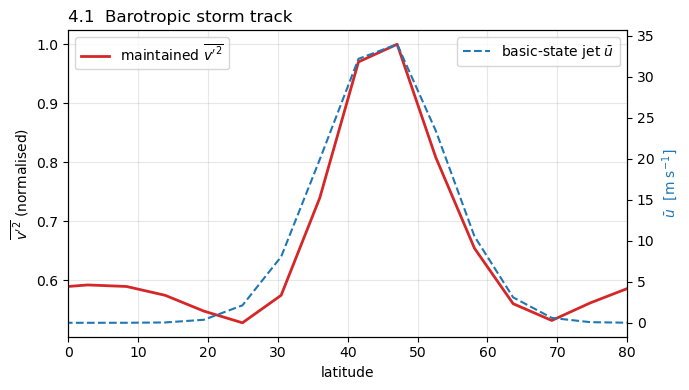

The stochastically maintained eddy variance peaks on the jet: the basic flow organises a storm track out of spatially white forcing.


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lat, v2/ v2.max(), "C3", lw=2, label=r"maintained $\overline{v'^2}$")
ax.set_xlabel("latitude"); ax.set_ylabel(r"$\overline{v'^2}$ (normalised)")
ax.set_xlim(0, 80); ax.set_title("4.1  Barotropic storm track", loc="left")
ax2 = ax.twinx()
ax2.plot(lat, ujet, "C0--", lw=1.5, label=r"basic-state jet $\bar u$")
ax2.set_ylabel(r"$\bar u$  [m s$^{-1}$]", color="C0")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
print("The stochastically maintained eddy variance peaks on the jet: the basic "
      "flow organises a storm track out of spatially white forcing.")

## 4.2 Why the jet organises the variance

The forcing is spatially **white** — it has no preferred latitude. The peak at
the jet therefore comes entirely from the operator $\mathbf{A}$: the sheared flow
is **non-normal**, so it amplifies and propagates disturbances preferentially
along the jet, and the dissipation $r$ removes them elsewhere. The balance
between non-normal amplification and damping is what localises the storm track —
the central result of the barotropic storm-track model. The same Lyapunov
machinery applied to a two-jet or realistic climatological $\bar u$ reproduces
the observed Pacific and Atlantic storm tracks.

### Summary

| ingredient | here |
|---|---|
| forcing | white-in-space, white-in-time vorticity, $\mathbf{Q}=\mathbf{I}$ |
| response | stationary covariance $\mathbf{C}$ from the Lyapunov equation |
| diagnostic | meridional-wind variance $\overline{v'^2}$ |
| result | a storm track localised on the jet |

The STM is the **second-moment** companion of the first-moment steady response
([](03-steady-response.ipynb)): the steady response is $-\mathbf{A}^{-1}f$ for
a deterministic $f$; the storm track is the stationary covariance for a
stochastic $f$. Both read a physical quantity out of the same linear operator.